# Entraînement du MLP Walter

Ce notebook ne contient que la configuration et l'orchestration. Le chargement des données, le modèle, la validation croisée, l'arrêt anticipé et les checkpoints sont implémentés dans `src/py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'py' / 'fpga_targets.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Impossible de trouver la racine du projet.')

source_dir = PROJECT_ROOT / 'src' / 'py'
if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from training import (
    angular_error_deg,
    load_trained_model,
    load_training_dataset,
    save_training_result,
    train_cross_validated,
    validate_training_config,
)

ModuleNotFoundError: No module named 'torch'

## Configuration unique

`target_unit` indique l'unité du tableau `pos` dans le fichier NPZ. Le modèle prédit toujours des radians; l'erreur affichée est toujours en degrés.

In [6]:
config = {
    'dataset_name': 'dataset_walter.npz',
    'dataset_path': 'data/walter/dataset_walter.npz',
    'input_dim': 6,
    'output_dim': 2,
    'layers': (66, 50, 38, 28, 20),
    'activation': 'leaky_relu',       # relu, leaky_relu, gelu, sigmoid, tanh
    'target_unit': 'degrees',          # degrees or radians dans le fichier NPZ
    'optimizer': 'AdamW',              # Adam, AdamW, RMSprop
    'init_weight': 'glorot_uniform',
    'learning_rate': 1e-3,
    'batch_size': 32,
    'epochs': 100,
    'patience': 20,
    'nb_splits': 5,
    'shuffle': True,
    'random_state': 7,
    'save_dir': 'data/walter',
    'name': 'mlp_walter.pt',
}

config = validate_training_config(config)
config

{'dataset_name': 'dataset_walter.npz',
 'dataset_path': 'data/walter/dataset_walter.npz',
 'input_dim': 6,
 'output_dim': 2,
 'layers': (66, 50, 38, 28, 20),
 'activation': 'leaky_relu',
 'target_unit': 'degrees',
 'optimizer': 'AdamW',
 'init_weight': 'glorot_uniform',
 'learning_rate': 0.001,
 'batch_size': 32,
 'epochs': 100,
 'patience': 20,
 'nb_splits': 5,
 'shuffle': True,
 'random_state': 7,
 'save_dir': 'data/walter',
 'name': 'mlp_walter.pt'}

## Chargement et validation des données

In [7]:
dataset = load_training_dataset(config, project_root=PROJECT_ROOT)
print(f'Dataset : {dataset.path}')
print(f'Entrées : {dataset.x.shape} {dataset.x.dtype}')
print(f'Cibles radians : {dataset.y_radians.shape} {dataset.y_radians.dtype}')

Dataset : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/walter/dataset_walter.npz
Entrées : (13640, 6) float32
Cibles radians : (13640, 2) float32


## Validation croisée et entraînement

In [8]:
result = train_cross_validated(config, project_root=PROJECT_ROOT)
scores_df = pd.DataFrame(result.fold_scores)
scores_df

Fold 1/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 1: early stopping at epoch 93 (best=0.6647 deg)


Fold 2/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 2: early stopping at epoch 85 (best=0.6727 deg)


Fold 3/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 3: early stopping at epoch 81 (best=0.6756 deg)


Fold 4/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 4: early stopping at epoch 47 (best=0.7473 deg)


Fold 5/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 5: early stopping at epoch 96 (best=0.6533 deg)


,fold,best_val_deg
0,1,0.664662
1,2,0.672722
2,3,0.675553
3,4,0.747258
4,5,0.653344


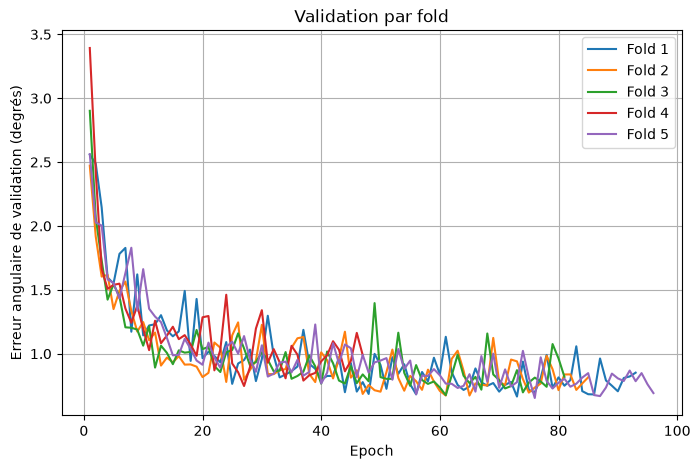

In [9]:
history_df = pd.DataFrame(result.history_rows)
fig, ax = plt.subplots(figsize=(8, 5))
for fold, history in history_df.groupby('fold'):
    ax.plot(history['epoch'], history['val_loss_deg'], label=f'Fold {fold}')
ax.set(
    xlabel='Epoch',
    ylabel='Erreur angulaire de validation (degrés)',
    title='Validation par fold',
)
ax.grid(True)
ax.legend()
plt.show()

## Sauvegarde du meilleur modèle

Le format reste compatible avec la suite du pipeline : `model_state_dict`, `config`, `best_global_fold` et `best_global_val` sont conservés.

In [10]:
model_path = save_training_result(result, project_root=PROJECT_ROOT)
print(f'Modèle sauvegardé : {model_path}')
print(f'Meilleur fold : {result.best_fold}')
print(f'Meilleure validation : {result.best_val_deg:.6f} degrés')

Modèle sauvegardé : /home/armel/Documents/PHD/MLP-GitLab/MLP_HLS/data/walter/mlp_walter.pt
Meilleur fold : 5
Meilleure validation : 0.653344 degrés


## Vérification rapide du checkpoint

In [11]:
model, checkpoint = load_trained_model(model_path, device=result.device)
with torch.no_grad():
    x_test = torch.from_numpy(dataset.x[:10]).to(result.device)
    y_test = torch.from_numpy(dataset.y_radians[:10]).to(result.device)
    predictions = model(x_test)
    errors = angular_error_deg(y_test, predictions, reduction='none')

print('Prédictions (radians) :')
print(predictions.cpu().numpy())
print('Erreurs angulaires (degrés) :')
print(errors.cpu().numpy())

Prédictions (radians) :
[[-0.21079291  0.04740645]
 [-0.24253109  0.3087054 ]
 [ 0.46302038 -0.11992738]
 [-0.25856793  0.40286157]
 [-0.16179758  0.4121548 ]
 [ 0.39234233 -0.07933474]
 [-0.15161046  0.16484752]
 [-0.02232963  0.3795796 ]
 [-0.34911615  0.3036783 ]
 [-0.22990394  0.13471177]]
Erreurs angulaires (degrés) :
[1.2186558  0.7846454  1.128956   1.3181881  0.9372178  3.1109018
 0.9627886  0.76600176 1.3994087  1.2304512 ]
